In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/Churn_Modelling.csv")
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [2]:
df.shape

(10000, 14)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [4]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


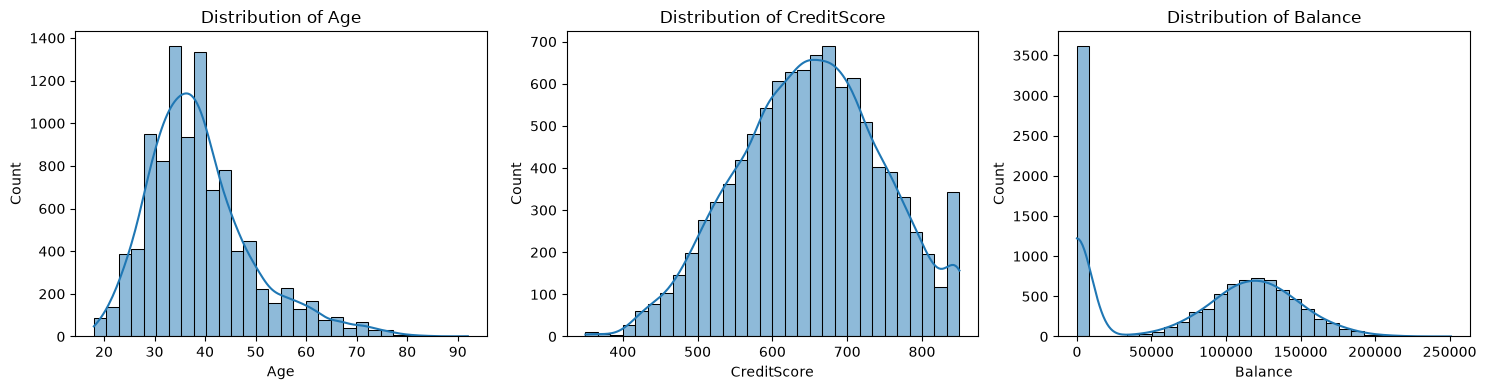

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
features = ["Age", "CreditScore", "Balance"]

for ax, feature in zip(axes, features):
    sns.histplot(data=df, x=feature, bins=30, kde=True, ax=ax)
    ax.set_title(f"Distribution of {feature}")

plt.tight_layout()
plt.show()

Age is right-skewed, credit scores are approximately normally distributed, and balances have a large concentration at zero. These distributions help explain the differences in mean, median, variance, and standard deviation across features.

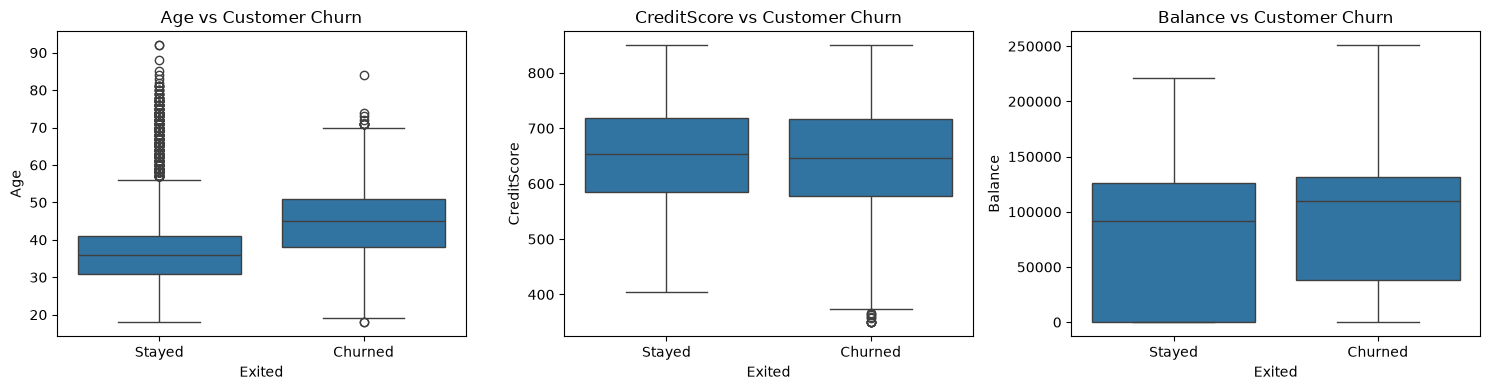

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
features = ["Age", "CreditScore", "Balance"]

for ax, feature in zip(axes, features):
    sns.boxplot(data=df, x="Exited", y=feature, ax=ax)
    ax.set_title(f"{feature} vs Customer Churn")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Stayed", "Churned"])

plt.tight_layout()
plt.show()

Customers who churn tend to be older and have slightly higher balances, while credit scores are similar between groups. The boxplots illustrate differences in median, variability, and outliers, helping identify potentially useful predictive features.

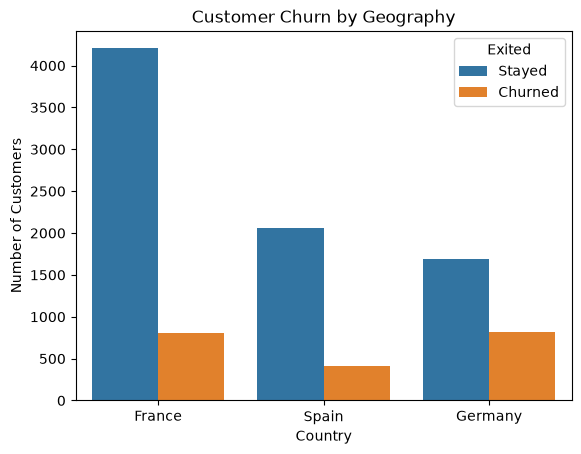

In [7]:
sns.countplot(data=df, x="Geography", hue="Exited")
plt.title("Customer Churn by Geography")
plt.xlabel("Country")
plt.ylabel("Number of Customers")
plt.legend(title="Exited", labels=["Stayed", "Churned"])
plt.show()

Comparing churn rates rather than raw counts accounts for differences in group size and helps identify relationships between categorical features and the target variable.

In [8]:
df.groupby("Geography")["Exited"].mean() * 100

Geography
France     16.154767
Germany    32.443204
Spain      16.673395
Name: Exited, dtype: float64

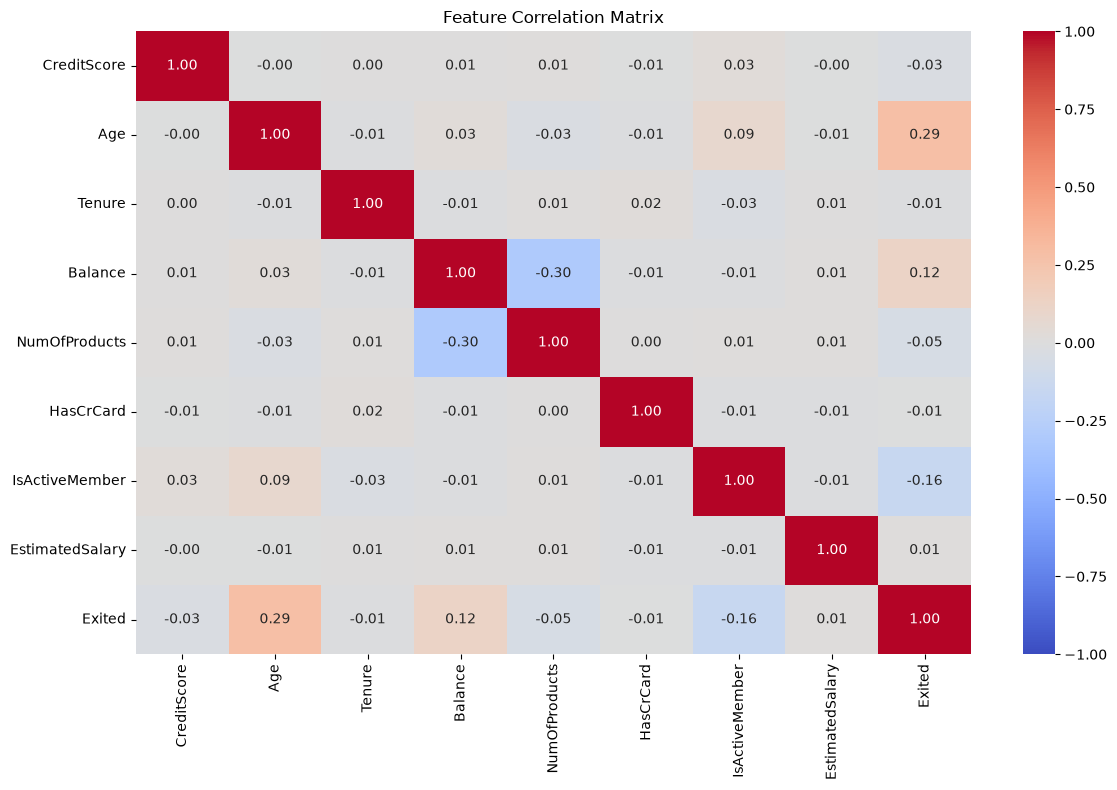

In [9]:
corr_matrix = df.drop(columns=["RowNumber", "CustomerId"]).select_dtypes(include="number").corr()
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

Age has the strongest positive correlation with churn (0.29), while active membership has a negative correlation (-0.16). This demonstrates Pearson correlation, which measures the direction and strength of linear relationships between numerical variables.

In [10]:
age_bins = [18, 30, 40, 50, 60, 100]
age_labels = ["18-30", "31-40", "41-50", "51-60", "61+"]

df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

churn_by_age = df.groupby(
    "AgeGroup",
    observed=True
)["Exited"].mean() * 100

print(churn_by_age)

AgeGroup
18-30     7.520325
31-40    12.087171
41-50    33.965517
51-60    56.210790
61+      24.784483
Name: Exited, dtype: float64


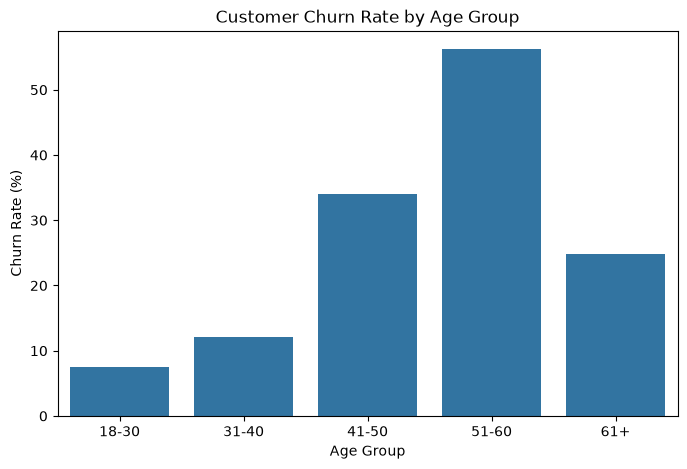

In [11]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=churn_by_age.index,
    y=churn_by_age.values
)

plt.title("Customer Churn Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Churn Rate (%)")
plt.show()

This suggests a nonlinear relationship between age and churn, which may be better captured by decision trees than by basic logistic regression.